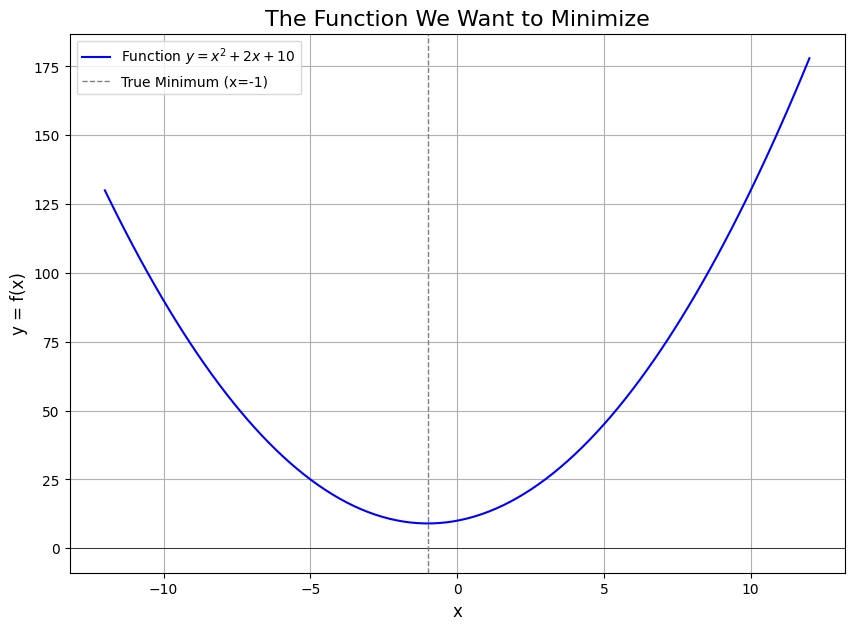

In [1]:
# gradient_descent_demo.py
#
# This script provides a simple from-scratch demonstration of the
# gradient descent algorithm. It finds the minimum of the
# quadratic function y = x^2 + 2x + 10.

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd # Import pandas

# --- 1. Define the Function and its Gradient ---

# The function we want to minimize: y = x^2 + 2x + 10
def f(x):
    return x**2 + 2*x + 10

# The gradient (derivative) of the function: y' = 2x + 2
# The gradient tells us the slope (direction) of the curve at any point.
def df(x):
    return 2*x + 2

# --- 2. Plot the Initial Function ---
# Create a range of x values to plot the function's curve
x_curve = np.linspace(-12, 12, 100)
y_curve = f(x_curve)

plt.figure(figsize=(10, 7))
plt.plot(x_curve, y_curve, 'b-', label='Function $y = x^2 + 2x + 10$')
plt.title('The Function We Want to Minimize', fontsize=16)
plt.xlabel('x', fontsize=12)
plt.ylabel('y = f(x)', fontsize=12)
plt.legend()
plt.grid(True)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(-1, color='grey', linestyle='--', linewidth=1.0, label='True Minimum (x=-1)')
plt.legend()
plt.show()



In [2]:

# --- 3. Set Hyperparameters ---
# We must provide an initial guess (starting point)
current_x = 10.0
# The learning_rate controls how big of a step we take
learning_rate = 0.1
# The number of steps (iterations) we will take
epochs = 25

print(f"--- Gradient Descent ---")
print(f"Function: y = x^2 + 2x + 10")
print(f"Gradient: y' = 2x + 2")
print(f"Starting at x = {current_x}")
print(f"Learning Rate = {learning_rate}")


# We will store the path of our descent to plot it later
df_data = [] # Use a list to store dictionaries (renamed from data_log)


--- Gradient Descent ---
Function: y = x^2 + 2x + 10
Gradient: y' = 2x + 2
Starting at x = 10.0
Learning Rate = 0.1


In [3]:

# --- 4. Run the Gradient Descent Loop ---
# The for loop is essential for gradient descent as it's an
# iterative algorithm where each step depends on the last.
for i in range(epochs):
    # Calculate the y-value at our current x
    current_y = f(current_x)

    # Calculate the gradient (slope) at our current position
    gradient = df(current_x)

    # Calculate the next x value
    next_x = current_x - (learning_rate * gradient)

    # Log all values for the DataFrame
    df_data.append({
        'Epoch': i,
        'x': current_x,
        'f(x)': current_y,
        "f'(x) (Gradient)": gradient,
        'Next x': next_x
    })


    # The core step: Move x in the *opposite* direction of the gradient.
    current_x = next_x # Update x to the new value


In [4]:

# --- 5. Create and Print DataFrame ---
df = pd.DataFrame(df_data).set_index('Epoch') # Renamed to 'df'

print("\n--- Gradient Descent Step-by-Step ---")
# Use to_string to ensure the full DataFrame is printed
print(df.to_string(float_format="%.4f"))

print("-" * 30)
# The true minimum is at x = -1
print(f"Gradient descent complete. Final position: x={current_x:.4f} (True minimum is at x=-1)")



--- Gradient Descent Step-by-Step ---
            x     f(x)  f'(x) (Gradient)  Next x
Epoch                                           
0     10.0000 130.0000           22.0000  7.8000
1      7.8000  86.4400           17.6000  6.0400
2      6.0400  58.5616           14.0800  4.6320
3      4.6320  40.7194           11.2640  3.5056
4      3.5056  29.3004            9.0112  2.6045
5      2.6045  21.9923            7.2090  1.8836
6      1.8836  17.3151            5.7672  1.3069
7      1.3069  14.3216            4.6137  0.8455
8      0.8455  12.4058            3.6910  0.4764
9      0.4764  11.1797            2.9528  0.1811
10     0.1811  10.3950            2.3622 -0.0551
11    -0.0551   9.8928            1.8898 -0.2441
12    -0.2441   9.5714            1.5118 -0.3953
13    -0.3953   9.3657            1.2095 -0.5162
14    -0.5162   9.2340            0.9676 -0.6130
15    -0.6130   9.1498            0.7741 -0.6904
16    -0.6904   9.0959            0.6192 -0.7523
17    -0.7523   9.0614        

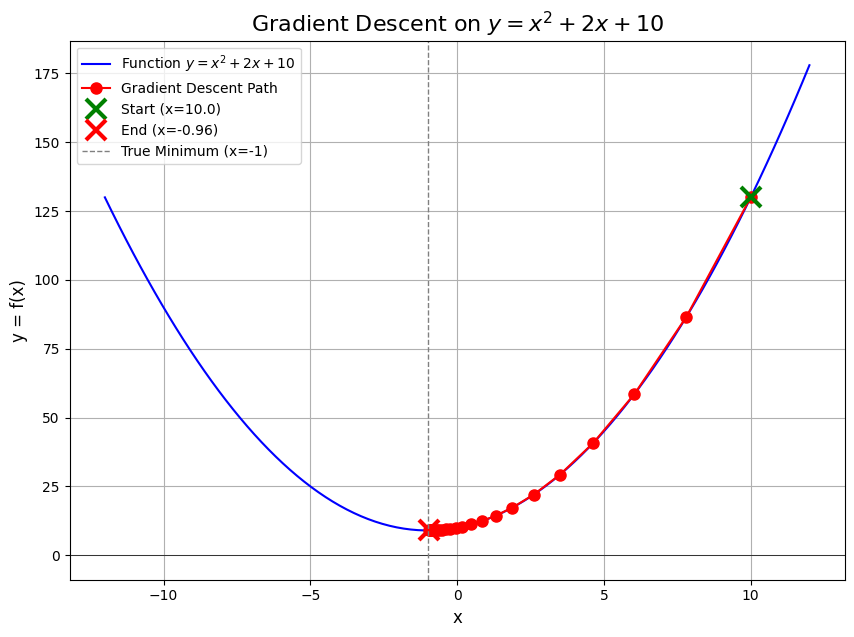

In [5]:

# --- 6. Plot the Results ---
# We already have x_curve and y_curve from section 2

# Extract path from the DataFrame
path_x = df['x'].values # Use 'df'
path_y = df['f(x)'].values # Use 'df'

plt.figure(figsize=(10, 7))
# Plot the function's curve
plt.plot(x_curve, y_curve, 'b-', label='Function $y = x^2 + 2x + 10$')
# Plot the path our algorithm took
plt.plot(path_x, path_y, 'ro-', markersize=8, label='Gradient Descent Path')
# Mark the starting point
plt.plot(path_x[0], path_y[0], 'gx', markersize=15, mew=3, label=f'Start (x={path_x[0]})')
# Mark the ending point (the final value of current_x after the loop)
final_y = f(current_x)
plt.plot(current_x, final_y, 'rx', markersize=15, mew=3, label=f'End (x={current_x:.2f})')

plt.title('Gradient Descent on $y = x^2 + 2x + 10$', fontsize=16)
plt.xlabel('x', fontsize=12)
plt.ylabel('y = f(x)', fontsize=12)
plt.legend()
plt.grid(True)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(-1, color='grey', linestyle='--', linewidth=1.0, label='True Minimum (x=-1)')
plt.legend()
plt.show()

